In [76]:
import pandas as pd
import numpy as np
import matplotlib as plot

df_customers = pd.read_csv("Datasets/customers.csv")
df_order_details = pd.read_csv("Datasets/order_details.csv")
df_orders = pd.read_csv("Datasets/orders.csv")
df_products = pd.read_csv("Datasets/products.csv")
df_returns = pd.read_csv("Datasets/returns.csv")

# print(customers_DS)

In [8]:
df_customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   CustomerID    500 non-null    str  
 1   CustomerName  500 non-null    str  
 2   Segment       500 non-null    str  
 3   Region        500 non-null    str  
 4   City          500 non-null    str  
 5   SignupDate    500 non-null    str  
dtypes: str(6)
memory usage: 51.5 KB


In [9]:
df_order_details.info()

<class 'pandas.DataFrame'>
RangeIndex: 7257 entries, 0 to 7256
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   DetailID   7257 non-null   str    
 1   OrderID    7257 non-null   str    
 2   ProductID  7257 non-null   str    
 3   UnitPrice  7257 non-null   float64
 4   Quantity   7257 non-null   int64  
 5   Discount   7257 non-null   float64
 6   Revenue    7257 non-null   float64
 7   Profit     7257 non-null   float64
dtypes: float64(4), int64(1), str(3)
memory usage: 645.0 KB


In [10]:
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   OrderID      2500 non-null   str  
 1   OrderDate    2500 non-null   str  
 2   CustomerID   2500 non-null   str  
 3   ShipMode     2500 non-null   str  
 4   OrderStatus  2500 non-null   str  
dtypes: str(5)
memory usage: 216.0 KB


In [11]:
df_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    45 non-null     str    
 1   ProductName  45 non-null     str    
 2   Category     45 non-null     str    
 3   SubCategory  45 non-null     str    
 4   CostPrice    45 non-null     float64
 5   UnitPrice    45 non-null     float64
dtypes: float64(2), str(4)
memory usage: 4.1 KB


In [12]:
df_returns.info()

<class 'pandas.DataFrame'>
RangeIndex: 342 entries, 0 to 341
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   ReturnID      342 non-null    str  
 1   DetailID      342 non-null    str  
 2   ReturnReason  342 non-null    str  
 3   ReturnDate    342 non-null    str  
dtypes: str(4)
memory usage: 25.0 KB


In [33]:
# Clean merge option
df_merged = pd.merge(
    df_order_details, 
    df_products[['ProductID', 'ProductName', 'Category', 'SubCategory', 'CostPrice']], 
    on="ProductID", 
    how="left"
)

In [36]:
df_merged.to_csv("merged.csv")

In [34]:
df_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 7257 entries, 0 to 7256
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DetailID     7257 non-null   str    
 1   OrderID      7257 non-null   str    
 2   ProductID    7257 non-null   str    
 3   UnitPrice    7257 non-null   float64
 4   Quantity     7257 non-null   int64  
 5   Discount     7257 non-null   float64
 6   Revenue      7257 non-null   float64
 7   Profit       7257 non-null   float64
 8   ProductName  7257 non-null   str    
 9   Category     7257 non-null   str    
 10  SubCategory  7257 non-null   str    
 11  CostPrice    7257 non-null   float64
dtypes: float64(5), int64(1), str(6)
memory usage: 1.1 MB


In [ ]:
# Task 1: Negative profit analysis
# df_merged.groupby(by="ProductID")["Profit"].sum().loc[lambda x: x<=0]
df_negative_profit = df_merged[df_merged["Profit"]<0]

pct_negative = ((len(df_negative_profit))/(len(df_merged))) * 100
print(pct_negative)

32.60300399614165


In [50]:
df_order_details[["Discount","Profit"]]

,Discount,Profit
0,0.00,154.48
1,0.00,318.48
2,0.05,-688.27
3,0.00,89.35
4,0.10,428.67
...,...,...
7252,0.00,548.40
7253,0.30,-172.22
7254,0.20,979.61
7255,0.00,1252.14


In [ ]:
# correlation = df_order_details["Discount"].corr(df_order_details["Profit"])
# print(correlation)

-0.39118959142889015


In [ ]:
# Task 2: Discount vs. Profit correlation
df_grouped = df_order_details.groupby("Discount")[["Profit","Revenue"]].agg(["mean","sum"])
df_grouped = df_grouped.drop(columns=[('Profit', 'sum'),('Revenue', 'mean')])

In [59]:
df_grouped

,Profit,Revenue
,mean,sum
Discount,,
0.00,602.964978,5801444.92
0.05,503.662737,1735968.24
0.10,394.844690,1665339.02
0.20,213.176501,1439818.44
0.30,-7.249857,1563229.21
0.40,-226.035401,1066453.87


In [ ]:
# Task 3: Outlier Detection (Quantity & Revenue)
Q1_Quantity = df_order_details["Quantity"].quantile(0.25)
Q3_Quantity = df_order_details["Quantity"].quantile(0.75)
IQR_Quantity = Q3_Quantity - Q1_Quantity

lower_bound_Quantity = Q1_Quantity - 1.5 * IQR_Quantity
upper_bound_Quantity = Q3_Quantity + 1.5 * IQR_Quantity

df_Quantity_outlier = df_order_details[(df_order_details["Quantity"] > upper_bound_Quantity ) | (df_order_details["Quantity"] < lower_bound_Quantity)]
len(df_Quantity_outlier)

0

In [ ]:
Q1_Revenue = df_order_details["Revenue"].quantile(0.25)
Q3_Revenue = df_order_details["Revenue"].quantile(0.75)
IQR_Revenue = Q3_Revenue - Q1_Revenue

lower_bound_Revenue = Q1_Revenue - 1.5 * IQR_Revenue
upper_bound_Revenue = Q3_Revenue + 1.5 * IQR_Revenue


df_Revenue_outlier = df_order_details[(df_order_details["Revenue"] > upper_bound_Revenue ) | (df_order_details["Revenue"] < lower_bound_Revenue)]
len(df_Revenue_outlier)

172

In [75]:
df_order_details[["Quantity","Profit"]].describe()

,Quantity,Profit
count,7257.000000,7257.000000
mean,5.533140,338.083088
std,2.896417,751.095485
min,1.000000,-2355.200000
25%,3.000000,-55.900000
50%,6.000000,158.420000
75%,8.000000,598.380000
max,10.000000,4173.800000


<Axes: >

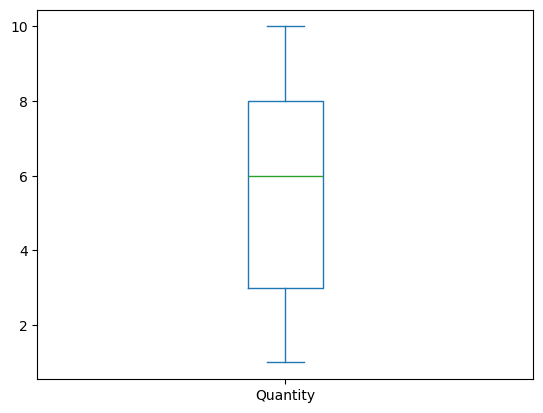

In [80]:
df_order_details["Quantity"].plot(kind="box")

<Axes: >

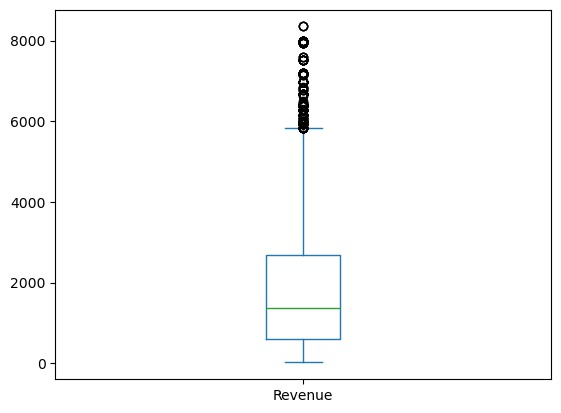

In [95]:
df_order_details["Revenue"].plot(kind="box")

In [96]:
# 1. Merge all 5 tables
df_master = df_order_details.merge(df_orders, on='OrderID', how='left') \
                            .merge(df_customers, on='CustomerID', how='left') \
                            .merge(df_products[['ProductID', 'ProductName', 'Category', 'SubCategory', 'CostPrice']], on='ProductID', how='left') \
                            .merge(df_returns[['DetailID', 'ReturnID', 'ReturnReason', 'ReturnDate']], on='DetailID', how='left')

# 2. Create IsReturned flag (1 if returned, 0 if not)
df_master['IsReturned'] = df_master['ReturnID'].notna().astype(int)

# 3. Convert dates to datetime format
df_master['OrderDate'] = pd.to_datetime(df_master['OrderDate'])
df_master['SignupDate'] = pd.to_datetime(df_master['SignupDate'])
df_master['ReturnDate'] = pd.to_datetime(df_master['ReturnDate'])

# 4. Verify shape and data types
print("df_master Shape:", df_master.shape)
df_master.info()

df_master Shape: (7257, 25)
<class 'pandas.DataFrame'>
RangeIndex: 7257 entries, 0 to 7256
Data columns (total 25 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   DetailID      7257 non-null   str           
 1   OrderID       7257 non-null   str           
 2   ProductID     7257 non-null   str           
 3   UnitPrice     7257 non-null   float64       
 4   Quantity      7257 non-null   int64         
 5   Discount      7257 non-null   float64       
 6   Revenue       7257 non-null   float64       
 7   Profit        7257 non-null   float64       
 8   OrderDate     7257 non-null   datetime64[us]
 9   CustomerID    7257 non-null   str           
 10  ShipMode      7257 non-null   str           
 11  OrderStatus   7257 non-null   str           
 12  CustomerName  7257 non-null   str           
 13  Segment       7257 non-null   str           
 14  Region        7257 non-null   str           
 15  City          7257 no

In [ ]:
from sqlalchemy import create_engine

# 1. PostgreSQL Connection Parameters
DB_USER = 'postgres'        # Your Postgres username (default is usually 'postgres')
DB_PASS = '123456'   # Replace with your actual database password
DB_HOST = 'localhost'       # Or your remote host IP
DB_PORT = '5432'            # Default PostgreSQL port is 5432
DB_NAME = 'apex_retail.db'     # Make sure you created this DB in PostgreSQL/pgAdmin first!

# 2. Create SQLAlchemy Database Engine
engine = create_engine(f'postgresql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}')

# 3. Write DataFrames directly to PostgreSQL tables
df_customers.to_sql('customers', engine, if_exists='replace', index=False)
df_products.to_sql('products', engine, if_exists='replace', index=False)
df_orders.to_sql('orders', engine, if_exists='replace', index=False)
df_order_details.to_sql('order_details', engine, if_exists='replace', index=False)
df_returns.to_sql('returns', engine, if_exists='replace', index=False)

print("All 5 tables successfully loaded into PostgreSQL database 'apex_retail'!")

All 5 tables successfully loaded into PostgreSQL database 'apex_retail'!
